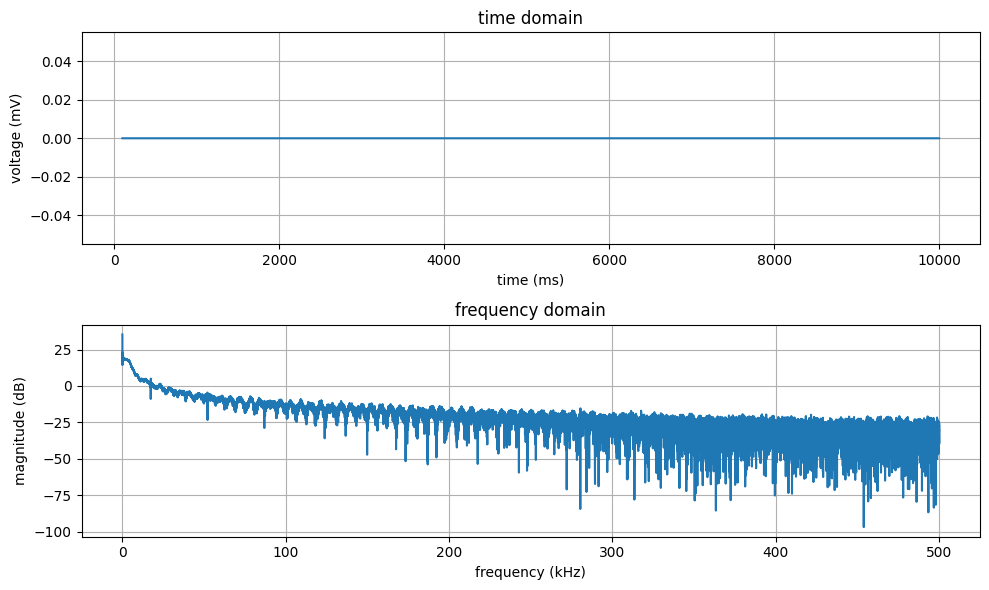

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from pydwf import DwfLibrary
from pydwf.utilities import openDwfDevice

# connect to AD3
dwf = DwfLibrary()
device = openDwfDevice(dwf)
scope = device.analogIn

# configure acquisition
sample_rate = 1e6  # 1 MS/s - adjust as needed
num_samples = 10000000
channel = 0

scope.channelEnableSet(channel, True)
scope.channelRangeSet(channel, 0.1)  # 100mV range - adjust if clipping
scope.frequencySet(sample_rate)
scope.bufferSizeSet(num_samples)

# acquire
scope.configure(reconfigure=True, start=True)

import time
while True:
    status = scope.status(read_data_flag=True)
    if status.name == "Done":
        break
    time.sleep(0.01)

# read samples
samples = scope.statusData(channel, num_samples)
samples = np.array(samples)

# time axis
t = np.arange(num_samples) / sample_rate

# plot time domain
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))
skip = int(num_samples*0.01)
ax1.plot(t[skip:] * 1000, samples[skip:] * 1000)
ax1.set_xlabel("time (ms)")
ax1.set_ylabel("voltage (mV)")
ax1.set_title("time domain")
ax1.grid(True)

# plot FFT
freqs = np.fft.rfftfreq(num_samples, 1/sample_rate)
fft_mag = np.abs(np.fft.rfft(samples))
fft_db = 20 * np.log10(fft_mag + 1e-12)

ax2.plot(freqs / 1000, fft_db)
ax2.set_xlabel("frequency (kHz)")
ax2.set_ylabel("magnitude (dB)")
ax2.set_title("frequency domain")
ax2.grid(True)

plt.tight_layout()
plt.show()

# cleanup
device.close()

In [16]:
device.close()